In [ ]:
import pathlib
import re
import time
import warnings

import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import legacy as pfl
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib import osf_fetch

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*experimental.*")
# Computer Modern math, e.g., for italic site class qualifiers
plt.rcParams["mathtext.fontset"] = "cm"

# samples of the same run's fossils, by OSF slug: uniform within
# (layer, subgrid) strata, and from a subset of spatial k-d tree groups
SAMPLES = {"uniform": "68tgv", "kdtree": "gqt5d"}
NUM_SITES = 16
ALPHA = 0.05
# minimum gap enforced between a node's origin time and its parent's
ORIGIN_TIME_EPSILON = 0.5
NUM_BOOTSTRAP = 0
SEED = 1
# dark, middle, and light shades per site class; plots use the middle
ETI_PALETTE = {
    "MLS": ["#004C7A", "#0072B2", "#8FC3E6"],
    "BENwg": ["#00664F", "#009E73", "#8ED6BE"],
    "DELbg": ["#9A3F00", "#D55E00", "#F2B48A"],
    "neutral": ["#6E6E6E", "#A6A6A6", "#DADADA"],
}

In [ ]:
def gap_points(*artists):
    """Draw point-plot markers as gaps in their connecting lines, layered as:
    connecting line, white gap, error bar, white halo, then a small dot
    marking each position."""
    for artist in artists:
        if artist is None:
            continue
        for line in [*artist.get_lines()]:
            if line.get_marker() in ("None", None, ""):
                line.set_zorder(3)  # error bars (and reference lines)
                continue
            _is_axes = hasattr(artist, "plot")
            if not _is_axes:
                # legend entries: just a dot
                line.set_linestyle("none")
                line.set_markerfacecolor(line.get_color())
                line.set_markersize(7)
                line.set_markeredgewidth(0)
                continue
            # connecting line below a white gap
            line.set_zorder(1)
            if not len(line.get_xdata()):
                continue
            _xy = line.get_xdata(), line.get_ydata()
            artist.plot(
                *_xy,
                linestyle="none",
                marker="o",
                markersize=9,
                markeredgewidth=0,
                color="white",
                zorder=2,
            )
            line.set_marker("None")
            # white halo, then small dot, above the error bar
            for _size, _color, _z in (
                (3.6, "white", 4),
                (2.2, line.get_color(), 5),
            ):
                artist.plot(
                    *_xy,
                    linestyle="none",
                    marker="o",
                    markersize=_size,
                    markeredgewidth=0,
                    color=_color,
                    zorder=_z,
                )

In [ ]:
def effect_pct(effect):
    """Express an effect size as a percent label, passing "neu" through."""
    return (
        effect
        if effect in ("neu", "neutral")
        else f"{float(effect) * 100:.1f}"
    )

In [ ]:
def right_legend(g):
    """Replace a FacetGrid's legend with a single-column legend to the right
    of the panels, vertically centered on them."""
    _handles = [*g.legend.legend_handles]
    _labels = [_text.get_text() for _text in g.legend.get_texts()]
    g.legend.remove()
    g._legend = None
    g.tight_layout()
    _boxes = [_ax.get_position() for _ax in g.axes.flat]
    return g.figure.legend(
        _handles,
        _labels,
        loc="center left",
        bbox_to_anchor=(
            max(_b.x1 for _b in _boxes) + 0.02,
            (min(_b.y0 for _b in _boxes) + max(_b.y1 for _b in _boxes)) / 2,
        ),
        ncol=1,
        frameon=False,
        handlelength=0.8,
        handletextpad=0.5,
        labelspacing=1.0,
    )

In [ ]:
def corner_xlabel(g, legend, text="Effect\nSize (%)"):
    """Place the x axis label at bottom right, left-aligned under the legend
    and level with the bottom of the bottom-left panel's tick labels."""
    _renderer = g.figure.canvas.get_renderer()
    _to_fig = g.figure.transFigure.inverted()
    _axes = g.axes.flat
    _ticks = [
        _t.get_window_extent(_renderer).transformed(_to_fig)
        for _t in _axes[len(_axes) - 1].get_xticklabels()
    ]
    g.figure.text(
        legend.get_window_extent(_renderer).transformed(_to_fig).x0,
        min(_b.y0 for _b in _ticks),
        text,
        ha="left",
        va="bottom",
        fontsize=plt.rcParams["axes.labelsize"],
    )

In [ ]:
def tilt_xticklabels(g):
    """Rotate x tick labels vertical, anchored right on their ticks."""
    for _a in g.axes.flat:
        plt.setp(
            _a.get_xticklabels(),
            rotation=90,
            ha="right",
            va="center",
            rotation_mode="anchor",
        )

In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-11-08T15:58:02.838965+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 8.39.0

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 7.0.0-1017-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

marimo    : 0.23.2
numpy     : 2.1.2
polars    : 1.36.1
re        : 2.2.1
scipy     : 1.14.1
seaborn   : 0.13.2
matplotlib: 3.10.9
phyloframe: 0.14.0
teeplot   : 1.4.2
pandas    : 2.2.3

```

In [ ]:
mo.md(f"""
# MLS Individual-host Spectra, Full-grid Fossils: Uniform vs. k-d Tree Group Sampling

Compares two samples of fossil genomes from one full-grid run, to ask whether sampling densely within local spatial clusters (k-d tree groups) yields more information about trait gain rates than sampling uniformly, and whether that improves power to detect a trait's gain rate differing from neutral sites'.

Data were generated by [`wse-async-ga` `wsclust/2026-11-05-mls-indiv-spectra-fullgrid-fossils-kdtree`](https://github.com/mmore500/wse-async-ga/tree/290f36b2fe870864c2bcc54ab2e6f26583577e90/wsclust/2026-11-05-mls-indiv-spectra-fullgrid-fossils-kdtree) (in [mmore500/wse-async-ga#100](https://github.com/mmore500/wse-async-ga/pull/100)), with genome flavor `genome_mlsindivspectra_2026_11_03` and seed 1105, and are hosted at {", ".join(f"<https://osf.io/{slug}> ({sample})" for sample, slug in SAMPLES.items())}.
Both files are no-collapse minified phylogenies, so every sampled fossil genome is its own leaf, reconstructed with hstrat v1.27.0's empirical-Bayes origin times:

- **uniform** (`05-minify-phylo`): 4M fossil genomes sampled uniformly within (fossil layer, subgrid) strata, spread over the whole grid; and
- **kdtree** (`07-minify-phylo-kdtree`): fossils partitioned into 1,000 spatially compact groups by k-d tree over PE row and column; groups taken in random order (at least 50, and more until 4M genomes are available), then 4M genomes sampled uniformly from the chosen groups.

So, the kdtree sample has about as many genomes as the uniform one, packed into a few patches of the grid.
Denser sampling within patches should resolve more closely related genomes, so more gains should be seen on short branches and within multi-leaf clades, but the two samples see different parts of the run.

The genome carries three spectra of four sites each, with base effect sizes $s_i \\in [0.25, 0.05, 0.025, 0.01]$, plus four neutral sites:

- **MLS** sites (`MLS`) both are favored within a host and reduce transmission,
- **between-group deleterious** sites (`DELbg`) only reduce transmission, and
- **within-group beneficial** sites (`BENwg`) are only favored within a host.

Each population member is a host, and each sample's trait gains are fit with `alifestd_tgs_allmdc_estimate_polars` (mutationally defined clades of every size) and `alifestd_tgs_pendantmdc_estimate_polars` (pendant branches only) from [mmore500/phyloframe#131](https://github.com/mmore500/phyloframe/pull/131), as in `2026-11-03-mls-indiv-spectra-fullgrid-fossils`.
Times are in `origin_time` units (two per generation).
""")

# MLS Individual-host Spectra, Full-grid Fossils: Uniform vs. k-d Tree Group Sampling

Compares two samples of fossil genomes from one full-grid run, to ask whether sampling densely within local spatial clusters (k-d tree groups) yields more information about trait gain rates than sampling uniformly, and whether that improves power to detect a trait's gain rate differing from neutral sites'.

Data were generated by [`wse-async-ga` `wsclust/2026-11-05-mls-indiv-spectra-fullgrid-fossils-kdtree`](https://github.com/mmore500/wse-async-ga/tree/290f36b2fe870864c2bcc54ab2e6f26583577e90/wsclust/2026-11-05-mls-indiv-spectra-fullgrid-fossils-kdtree) (in [mmore500/wse-async-ga#100](https://github.com/mmore500/wse-async-ga/pull/100)), with genome flavor `genome_mlsindivspectra_2026_11_03` and seed 1105, and are hosted at <https://osf.io/68tgv> (uniform), <https://osf.io/gqt5d> (kdtree).
Both files are no-collapse minified phylogenies, so every sampled fossil genome is its own leaf, reconstructed with hstrat v1.27.0's empirical-Bayes origin times:

- **uniform** (`05-minify-phylo`): 4M fossil genomes sampled uniformly within (fossil layer, subgrid) strata, spread over the whole grid; and
- **kdtree** (`07-minify-phylo-kdtree`): fossils partitioned into 1,000 spatially compact groups by k-d tree over PE row and column; groups taken in random order (at least 50, and more until 4M genomes are available), then 4M genomes sampled uniformly from the chosen groups.

So, the kdtree sample has about as many genomes as the uniform one, packed into a few patches of the grid.
Denser sampling within patches should resolve more closely related genomes, so more gains should be seen on short branches and within multi-leaf clades, but the two samples see different parts of the run.

The genome carries three spectra of four sites each, with base effect sizes $s_i \in [0.25, 0.05, 0.025, 0.01]$, plus four neutral sites:

- **MLS** sites (`MLS`) both are favored within a host and reduce transmission,
- **between-group deleterious** sites (`DELbg`) only reduce transmission, and
- **within-group beneficial** sites (`BENwg`) are only favored within a host.

Each population member is a host, and each sample's trait gains are fit with `alifestd_tgs_allmdc_estimate_polars` (mutationally defined clades of every size) and `alifestd_tgs_pendantmdc_estimate_polars` (pendant branches only) from [mmore500/phyloframe#131](https://github.com/mmore500/phyloframe/pull/131), as in `2026-11-03-mls-indiv-spectra-fullgrid-fossils`.
Times are in `origin_time` units (two per generation).

## Get Data

In [ ]:
def _config_cols(names):
    return [
        name
        for name in names
        if name.startswith(("ASYNC_GA_", "CEREBRASLIB_", "dstream_algo"))
        or name.startswith(("mls_", "deleterious_", "beneficial_"))
        or name
        in (
            "config",
            "genomeFlavor",
            "globalSeed",
            "nCol",
            "nRow",
            "nColSubgrid",
            "nRowSubgrid",
            "nCycle",
            "tilePopSize",
            "replicate",
            "trait_focal",
        )
    ]

_rows = {}
for _sample, _slug in SAMPLES.items():
    _lazy = pl.scan_parquet(osf_fetch(_slug)).filter(
        pl.col("clade_size") > 0
    )
    assert _lazy.select(pl.col("config").n_unique()).collect().item() == 1
    _rows[_sample] = (
        _lazy.select(_config_cols(_lazy.collect_schema().names()))
        .head(1)
        .collect()
    )
_first, *_others = _rows.values()
# both samples are of one run
for _other in _others:
    assert _first.equals(_other.select(_first.columns)), "runs differ"
config_df = _first
assert config_df["nColSubgrid"].item() == 0, "expected full grid"
config_df.transpose(include_header=True)

downloading https://osf.io/68tgv/download -> /tmp/68tgv
size: 71920267 bytes
downloading https://osf.io/gqt5d/download -> /tmp/gqt5d
size: 73367921 bytes


column,column_0
str,str
"""trait_focal""","""65295"""
"""config""","""flavor=genome_mlsindivspectra_…"
"""replicate""","""26847dab-8496-4066-91a2-1b8d10…"
"""genomeFlavor""","""genome_mlsindivspectra_2026_11…"
"""globalSeed""","""1105"""
…,…
"""CEREBRASLIB_MLS_HOST_CLEAR_P""","""0.1"""
"""ASYNC_GA_FOSSIL_SAMPLING_MODE""","""reservoir"""
"""ASYNC_GA_GENOME_FLAVOR""","""genome_mlsindivspectra_2026_11…"


In [ ]:
# site class K's level-i site is flag byte B, bit b (trait site 8B + b),
# with transmission reduction (0 where a class lacks it) and within-host
# gain and loss probabilities
_config = config_df.row(0, named=True)
_site_cols = [
    (int(B) * 8 + int(b), kind, what, col)
    for col in config_df.columns
    for kind, what, B, b in re.findall(
        r"^(mls|deleterious|beneficial)"
        r"_(transmission_reduction|withinhost_gain|withinhost_loss)"
        r"_p_byte(\d+)_bit(\d+)$",
        col,
    )
]
effect_sizes = (
    pd.DataFrame(
        [
            {"site": site, "kind": kind, f"{what}_p": _config[col]}
            for site, kind, what, col in _site_cols
        ],
    )
    .groupby("site", as_index=False)
    .first()
)
_txscale = _config["CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE"]
_neutral_p = _config["mls_withinhost_neutral_p"]
# base effect size s_i is transmission reduction over its scale; within-
# host beneficial sites have none, so take s_i from the MLS site with the
# same within-host gain probability
effect_sizes["effect_size"] = (
    effect_sizes["transmission_reduction_p"] / _txscale
).round(6)
_is_mls = effect_sizes["kind"] == "mls"
_gain_to_s = dict(
    zip(
        effect_sizes.loc[_is_mls, "withinhost_gain_p"],
        effect_sizes.loc[_is_mls, "effect_size"],
    ),
)
_is_ben = effect_sizes["kind"] == "beneficial"
effect_sizes.loc[_is_ben, "effect_size"] = effect_sizes.loc[
    _is_ben, "withinhost_gain_p"
].map(_gain_to_s)
assert effect_sizes["effect_size"].notna().all()
# configured within-host gain probability relative to neutral sites'
effect_sizes["configured_gain_ratio"] = (
    effect_sizes["withinhost_gain_p"] / _neutral_p
)
focal_sites = sorted(effect_sizes["site"].unique().tolist())
_focal_mask = sum(1 << site for site in focal_sites)
assert config_df["trait_focal"].item() == _focal_mask, "focal mismatch"
neutral_sites = [
    site for site in range(NUM_SITES) if site not in focal_sites
]

# ETI evaluation bar notation: between-group effect above, within-group
# effect below, with null (crossed circle) for no effect
kind_labels = {
    "MLS": r"MLS$|^{-}_{+}$",
    "DELbg": r"DEL$\mathit{bg}|^{-}_{\varnothing}$",
    "BENwg": r"BEN$\mathit{wg}|^{\varnothing}_{+}$",
    "NEU": r"NEU$|^{\varnothing}_{\varnothing}$",
}
_kind_of = {
    "mls": kind_labels["MLS"],
    "deleterious": kind_labels["DELbg"],
    "beneficial": kind_labels["BENwg"],
}
_info = effect_sizes.set_index("site")
site_info = pd.DataFrame(
    {
        "site": range(NUM_SITES),
        "trait": [f"site{site}" for site in range(NUM_SITES)],
        "kind": [
            (
                _kind_of[_info.loc[site, "kind"]]
                if site in focal_sites
                else kind_labels["NEU"]
            )
            for site in range(NUM_SITES)
        ],
        "effect_size": [
            (
                effect_pct(_info.loc[site, "effect_size"])
                if site in focal_sites
                else "neu"
            )
            for site in range(NUM_SITES)
        ],
        "configured_gain_ratio": [
            (
                _info.loc[site, "configured_gain_ratio"]
                if site in focal_sites
                else 1.0
            )
            for site in range(NUM_SITES)
        ],
    },
)
kind_order = [
    kind_labels[_kind] for _kind in ("NEU", "BENwg", "DELbg", "MLS")
]
kind_palette = {
    kind_labels[_kind]: ETI_PALETTE[_key][1]
    for _kind, _key in (
        ("NEU", "neutral"),
        ("BENwg", "BENwg"),
        ("DELbg", "DELbg"),
        ("MLS", "MLS"),
    )
}
effect_size_order = ["neu"] + sorted(
    set(site_info["effect_size"]) - {"neu"}, key=float
)
mo.vstack([effect_sizes, site_info])

,site,kind,transmission_reduction_p,withinhost_gain_p,withinhost_loss_p,effect_size,configured_gain_ratio
0,0,beneficial,0.0000,8.271521e-05,1.986524e-07,0.250,82.715296
1,1,beneficial,0.0000,1.992270e-06,5.845754e-07,0.050,1.992272
2,2,beneficial,0.0000,1.389192e-06,7.486867e-07,0.025,1.389193
3,3,beneficial,0.0000,1.136100e-06,8.858464e-07,0.010,1.136102
4,8,mls,0.1250,8.271521e-05,1.986524e-07,0.250,82.715296
...,...,...,...,...,...,...,...
7,11,mls,0.0050,1.136100e-06,8.858464e-07,0.010,1.136102
8,12,deleterious,0.1250,9.999990e-07,9.999990e-07,0.250,1.000000
9,13,deleterious,0.0250,9.999990e-07,9.999990e-07,0.050,1.000000
10,14,deleterious,0.0125,9.999990e-07,9.999990e-07,0.025,1.000000


In [ ]:
def prep_phylogeny(data_path):
    """Load a no-collapse minified phylogeny, drop layer 0, prune, collapse
    unifurcations, and enforce positive branch lengths; mark clade sizes,
    survival times, and branch lengths. Returns the phylogeny (pandas) and
    a summary."""
    # unminify: rows are in depth-first order, with id = row index
    _raw = (
        pl.read_parquet(
            data_path,
            columns=[
                "ancestor_offset",
                "origin_time",
                "clade_size",
                "trait_present",
                "layer",
                "row",
                "col",
            ],
        )
        .with_row_index("id")
        .with_columns(
            pl.col("id").cast(pl.Int64),
            ancestor_id=(
                pl.col("id").cast(pl.Int64)
                - pl.col("ancestor_offset").cast(pl.Int64)
            ),
            trait_present=pl.col("trait_present").cast(pl.Int64),
            row=pl.col("row").cast(pl.Int64),
            col=pl.col("col").cast(pl.Int64),
            layer=pl.col("layer").cast(pl.Int64),
        )
        .drop("ancestor_offset")
        .to_pandas()
    )
    _num_raw = len(_raw)
    _is_genome = _raw["clade_size"] > 0
    assert (_raw.loc[_is_genome, "clade_size"] == 1).all(), "no-collapse"
    # a missing origin time (a root's) can be no later than the run start
    _no_time = _raw["origin_time"].isna()
    assert (
        _raw.loc[_no_time, "ancestor_id"] == _raw.loc[_no_time, "id"]
    ).all()
    _raw["origin_time"] = _raw["origin_time"].fillna(-1).astype(float)
    phylo = (
        _raw.drop(columns=["clade_size"])
        .assign(extant=_is_genome & (_raw["origin_time"] >= 0))
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_prune_extinct_lineages_asexual, mutate=True)
        .pipe(pfl.alifestd_collapse_unifurcations, mutate=True)
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_mark_leaves, mutate=True)
        .reset_index(drop=True)
    )
    del _raw
    assert (phylo["is_leaf"] == phylo["extant"]).all()
    phylo = phylo.drop(columns=["extant"])
    assert (phylo["id"] == np.arange(len(phylo))).all()
    _before = phylo["origin_time"].to_numpy().copy()
    phylo = pfl.alifestd_coerce_chronological_consistency(
        phylo, mutate=True, epsilon=ORIGIN_TIME_EPSILON
    )
    _after = phylo["origin_time"].to_numpy()
    phylo["num_leaves"] = phylo.pipe(
        pfl.alifestd_mark_num_leaves_asexual, mutate=True
    )["num_leaves"]
    phylo["max_descendant_origin_time"] = phylo.pipe(
        pfl.alifestd_mark_max_descendant_origin_time_asexual, mutate=True
    )["max_descendant_origin_time"]
    _anc = phylo["ancestor_id"].to_numpy()
    phylo["is_root"] = _anc == phylo["id"].to_numpy()
    phylo["branch_length"] = np.where(
        phylo["is_root"], np.nan, _after - _after[_anc]
    )
    phylo["survival_time"] = phylo["max_descendant_origin_time"] - _after
    summary = {
        "num_nodes_raw": _num_raw,
        "num_nodes": len(phylo),
        "num_leaves": int(phylo["is_leaf"].sum()),
        "num_inner": int((~phylo["is_leaf"]).sum()),
        "num_roots": int(phylo["is_root"].sum()),
        "num_origin_times_raised": int((_after != _before).sum()),
    }
    return phylo, summary

In [ ]:
def add_trait_transitions(phylo):
    """Add each site's state transition on the branch into each node, from
    leaf states under parsimony without loss (a node has a trait if and
    only if every leaf of its clade does). Returns the column names."""
    _is_leaf = phylo["is_leaf"].to_numpy()
    _anc = phylo["ancestor_id"].to_numpy()
    _is_root = phylo["is_root"].to_numpy()
    _num_leaves = phylo["num_leaves"].to_numpy()
    _present = phylo["trait_present"].fillna(0).to_numpy(dtype=np.int64)
    names = []
    for _site in range(NUM_SITES):
        _has = _is_leaf & (((_present >> _site) & 1) != 0)
        _count = (
            phylo[["id", "ancestor_id"]]
            .copy()
            .pipe(
                pfl.alifestd_calc_clade_trait_count_asexual,
                mutate=True,
                trait_mask=_has,
            )
        )
        _state = (_count == _num_leaves).astype(np.int8)
        _name = f"site{_site}"
        phylo[_name] = _state - np.where(_is_root, 0, _state[_anc])
        assert phylo[_name].isin([0, 1]).all(), "parsimony without loss"
        names.append(_name)
    return names

In [ ]:
def measure_sampling(phylo):
    """Per-PE sampled genome counts, pendant branch lengths, and the
    spatial distance between leaves of cherries (two-leaf clades)."""
    # inner nodes have no PE, so row and col are float (with nan); leaves'
    # are whole
    _leaves = phylo.loc[phylo["is_leaf"]].astype({"row": int, "col": int})
    pe_counts = (
        _leaves.groupby(["row", "col"])
        .size()
        .rename("num_genomes")
        .reset_index()
    )
    pendant_lengths = _leaves["branch_length"].to_numpy(dtype=np.float32)
    # cherries: inner nodes whose two children are both leaves
    _anc = phylo["ancestor_id"].to_numpy()
    _child = ~phylo["is_root"].to_numpy()
    _num_children = np.bincount(_anc[_child], minlength=len(phylo))
    _leaf_children = np.bincount(
        _anc[_child & phylo["is_leaf"].to_numpy()], minlength=len(phylo)
    )
    _is_cherry = (_num_children == 2) & (_leaf_children == 2)
    _cherry_leaves = _leaves[_is_cherry[_leaves["ancestor_id"].to_numpy()]]
    _pairs = _cherry_leaves.sort_values("ancestor_id").groupby("ancestor_id")
    _first, _last = _pairs.first(), _pairs.last()
    cherry_distances = np.hypot(
        (_first["row"] - _last["row"]).to_numpy(),
        (_first["col"] - _last["col"]).to_numpy(),
    ).astype(np.float32)
    summary = {
        "num_pes_sampled": len(pe_counts),
        "genomes_per_sampled_pe": pe_counts["num_genomes"].mean(),
        "pendant_length_median": float(np.median(pendant_lengths)),
        "num_cherries": int(_is_cherry.sum()),
        "leaves_in_cherries_frac": 2 * _is_cherry.sum() / len(_leaves),
        "cherry_distance_median": float(np.median(cherry_distances)),
        "cherry_same_pe_frac": float((cherry_distances == 0).mean()),
    }
    return pe_counts, pendant_lengths, cherry_distances, summary

In [ ]:
def tabulate_sample_mdcs(phylo, trait_names):
    """One row per MDC (gain on a non-root branch), with its stem branch
    length, survival time, and size (leaves)."""
    _is_root = phylo["is_root"].to_numpy()
    _cols = ["origin_time", "branch_length", "survival_time", "num_leaves"]
    return pd.concat(
        [
            phylo.loc[
                (phylo[_name].to_numpy() == 1) & ~_is_root, _cols
            ].assign(trait=_name)
            for _name in trait_names
        ],
        ignore_index=True,
    )

In [ ]:
def fit_sample_estimates(phylo, trait_names, neutral_traits, batches):
    """Fit allmdc and pendant estimators, raw and calibrated, per batch of
    focal traits together with the neutral traits (to bound memory);
    neutral traits' fits must agree across batches."""
    _df = pl.from_pandas(
        phylo[["id", "ancestor_id", "origin_time", *trait_names]],
    )
    _results = []
    for _method, _fn in (
        ("allmdc", pfl.alifestd_tgs_allmdc_estimate_polars),
        ("pendantmdc", pfl.alifestd_tgs_pendantmdc_estimate_polars),
    ):
        for _calibrate in (False, True):
            _start = time.time()
            _fits = [
                _fn(
                    _df,
                    trait_transitions=[*_batch, *neutral_traits],
                    neutral_traits=neutral_traits,
                    calibrate=_calibrate,
                    num_bootstrap=NUM_BOOTSTRAP,
                    seed=SEED,
                ).to_pandas()
                for _batch in batches
            ]
            _neutral_fits = [
                _fit.set_index("trait").loc[
                    neutral_traits, ["gain_rate", "selection"]
                ]
                for _fit in _fits
            ]
            for _other in _neutral_fits[1:]:
                assert np.allclose(_neutral_fits[0], _other, rtol=1e-6)
            print(
                f"  {_method} calibrate={_calibrate}: "
                f"{time.time() - _start:.0f}s",
            )
            _results.append(
                pd.concat(
                    [
                        _fits[0][_fits[0]["trait"].isin(neutral_traits)],
                        *(
                            _fit[~_fit["trait"].isin(neutral_traits)]
                            for _fit in _fits
                        ),
                    ],
                    ignore_index=True,
                ).assign(
                    method=_method,
                    calibration="calibrated" if _calibrate else "raw",
                ),
            )
    return pd.concat(_results, ignore_index=True)

In [ ]:
mo.md(f"""
## Analyze Samples

Each sample is analyzed in turn, then its phylogeny is discarded to bound memory:

1. Fossil layer 0 (the initial population, at `origin_time == -1`) is dropped, lineages without retained leaves are pruned, and unifurcations collapsed.
2. Origin times are raised to at least the parent's plus {ORIGIN_TIME_EPSILON}, so every branch has positive length.
3. Each site's trait state at every node is reconstructed under parsimony without loss: a node has a trait if and only if every leaf of its clade does.
4. The allmdc and pendant estimators are fit with raw and with neutral-calibrated branch lengths.
""")

## Analyze Samples

Each sample is analyzed in turn, then its phylogeny is discarded to bound memory:

1. Fossil layer 0 (the initial population, at `origin_time == -1`) is dropped, lineages without retained leaves are pruned, and unifurcations collapsed.
2. Origin times are raised to at least the parent's plus 0.5, so every branch has positive length.
3. Each site's trait state at every node is reconstructed under parsimony without loss: a node has a trait if and only if every leaf of its clade does.
4. The allmdc and pendant estimators are fit with raw and with neutral-calibrated branch lengths.

In [ ]:
import gc

_neutral = [f"site{_site}" for _site in neutral_sites]
_batches = [
    _part["trait"].tolist()
    for _kind, _part in site_info.groupby("kind", sort=False)
    if not _kind.startswith("NEU")
]
_summaries, _pes, _pendants, _cherries, _mdcs, _estimates = (
    [],
    [],
    [],
    [],
    [],
    [],
)
for _sample, _slug in SAMPLES.items():
    print(f"{_sample} ({_slug})")
    _start = time.time()
    _phylo, _summary = prep_phylogeny(osf_fetch(_slug))
    _names = add_trait_transitions(_phylo)
    _pe, _pend, _cher, _density = measure_sampling(_phylo)
    _summaries.append({"sample": _sample, **_summary, **_density})
    _pes.append(_pe.assign(sample=_sample))
    _pendants.append(
        pd.DataFrame({"branch_length": _pend, "sample": _sample})
    )
    _cherries.append(pd.DataFrame({"distance": _cher, "sample": _sample}))
    _mdcs.append(
        tabulate_sample_mdcs(_phylo, _names).assign(sample=_sample)
    )
    _estimates.append(
        fit_sample_estimates(_phylo, _names, _neutral, _batches).assign(
            sample=_sample
        )
    )
    del _phylo
    gc.collect()
    print(f"  total {time.time() - _start:.0f}s")
sample_summary = pd.DataFrame(_summaries).set_index("sample").T
pe_counts = pd.concat(_pes, ignore_index=True)
pendant_lengths = pd.concat(_pendants, ignore_index=True)
cherry_distances = pd.concat(_cherries, ignore_index=True)
sample_mdcs = pd.concat(_mdcs, ignore_index=True).merge(
    site_info, on="trait"
)
sample_estimates = pd.concat(_estimates, ignore_index=True).merge(
    site_info, on="trait"
)
mo.Html(sample_summary.to_html(float_format="{:.4g}".format))

uniform (68tgv)
reusing cached /tmp/68tgv
size: 71920267 bytes


/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_calc_allmdc_nll.py:57: RuntimeWarning: overflow encountered in multiply
  p = gain_rate * effective_length * survival
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_calc_allmdc_nll.py:59: RuntimeWarning: invalid value encountered in multiply
  dnll_dlog_gain = np.sum(dnll_dp * p)
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_calc_allmdc_nll.py:64: RuntimeWarning: overflow encountered in multiply
  effective_length_deriv * survival
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_calc_allmdc_nll.py:65: RuntimeWarning: overflow encountered in multiply
  + effective_length * survival_deriv
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phylofr

  allmdc calibrate=False: 60s


/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_select_calibration_neighborhoods.py:62: UserWarning: 100 of 4096 calibration neighborhoods contain no neutral trait gains, so leaves there get zero effective pendant length; more neutral traits or leaves would help.
  warnings.warn(
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_select_calibration_neighborhoods.py:62: UserWarning: 2675 of 4096 calibration neighborhoods contain no neutral trait gains, so leaves there get zero effective pendant length; more neutral traits or leaves would help.
  warnings.warn(
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/_auxlib/_calc_binomial_nll_proxy.py:64: RuntimeWarning: overflow encountered in divide
  num_failures / (1 - clipped_p) - num_successes / clipped_p,
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/

  allmdc calibrate=True: 94s
  pendantmdc calibrate=False: 14s
  pendantmdc calibrate=True: 20s
  total 197s
kdtree (gqt5d)
reusing cached /tmp/gqt5d
size: 73367921 bytes


/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_calc_allmdc_nll.py:57: RuntimeWarning: overflow encountered in multiply
  p = gain_rate * effective_length * survival
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_calc_allmdc_nll.py:59: RuntimeWarning: invalid value encountered in multiply
  dnll_dlog_gain = np.sum(dnll_dp * p)
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_calc_allmdc_nll.py:64: RuntimeWarning: overflow encountered in multiply
  effective_length_deriv * survival
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_calc_allmdc_nll.py:65: RuntimeWarning: overflow encountered in multiply
  + effective_length * survival_deriv
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phylofr

  allmdc calibrate=False: 74s


/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_select_calibration_neighborhoods.py:62: UserWarning: 11 of 4096 calibration neighborhoods contain no neutral trait gains, so leaves there get zero effective pendant length; more neutral traits or leaves would help.
  warnings.warn(
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_select_calibration_neighborhoods.py:62: UserWarning: 957 of 4096 calibration neighborhoods contain no neutral trait gains, so leaves there get zero effective pendant length; more neutral traits or leaves would help.
  warnings.warn(
/home/runner/.cache/uv/archive-v0/40kO152yZnl_xiceFFxJr/lib/python3.10/site-packages/phyloframe/legacy/_impl/_tgs_select_calibration_neighborhoods.py:62: UserWarning: 2517 of 4096 calibration neighborhoods contain no neutral trait gains, so leaves there get zero effective pendant length; more neutral trait

  allmdc calibrate=True: 144s
  pendantmdc calibrate=False: 15s
  pendantmdc calibrate=True: 21s
  total 261s


sample,uniform,kdtree
num_nodes_raw,7.906e+06,7.878e+06
num_nodes,7.857e+06,7.824e+06
num_leaves,3.951e+06,3.946e+06
num_inner,3.906e+06,3.878e+06
num_roots,2.233e+05,2.185e+05
num_origin_times_raised,214,630
num_pes_sampled,8.745e+05,5.483e+04
genomes_per_sampled_pe,4.518,71.97
pendant_length_median,1677,504.7
num_cherries,1.18e+06,1.022e+06


## Sampling Density

Where each sample's genomes lie on the grid, how many share a processing element (PE), and how closely related sampled genomes are: pendant branch length (time back to a leaf's nearest sampled branching point) and the spatial distance between the two leaves of each cherry (two-leaf clade).

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/viz=pe-coverage+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/viz=pe-coverage+ext=.png


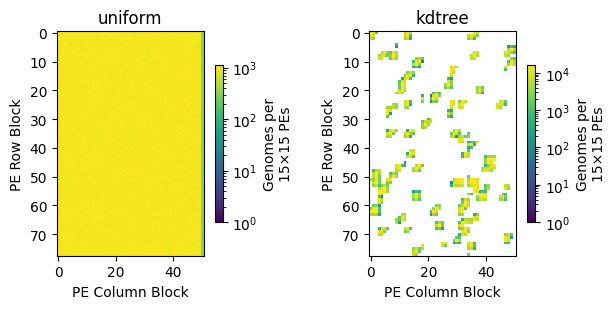

In [ ]:
_n_row, _n_col = int(config_df["nRow"].item()), int(
    config_df["nCol"].item()
)
# genomes per 15x15-PE block
_block = 15

def pe_coverage(data):
    _fig, _axes = plt.subplots(
        1, len(SAMPLES), figsize=(3.2 * len(SAMPLES), 3.2)
    )
    for _ax, _sample in zip(_axes, SAMPLES):
        _d = data[data["sample"] == _sample]
        _grid = np.zeros(
            (-(-_n_row // _block), -(-_n_col // _block)), dtype=float
        )
        np.add.at(
            _grid,
            (
                (_d["row"].to_numpy() // _block),
                (_d["col"].to_numpy() // _block),
            ),
            _d["num_genomes"].to_numpy(),
        )
        _im = _ax.imshow(
            np.where(_grid > 0, _grid, np.nan),
            cmap="viridis",
            norm=plt.matplotlib.colors.LogNorm(vmin=1),
            interpolation="nearest",
        )
        _ax.set_title(f"{_sample}")
        _ax.set_xlabel("PE Column Block")
        _ax.set_ylabel("PE Row Block")
        _fig.colorbar(
            _im,
            ax=_ax,
            shrink=0.7,
            label=f"Genomes per\n{_block}×{_block} PEs",
        )
    _fig.tight_layout()

tp.tee(
    pe_coverage,
    data=pe_counts,
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
)
plt.close("all")

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/hue=sample+kind=ecdf+viz=displot+what=pe-genomes+x=num-genomes+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/hue=sample+kind=ecdf+viz=displot+what=pe-genomes+x=num-genomes+ext=.png


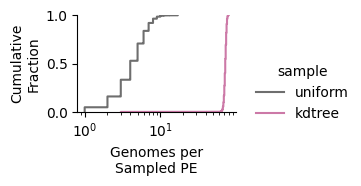

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/hue=sample+kind=ecdf+viz=displot+what=pendant-lengths+x=branch-length+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/hue=sample+kind=ecdf+viz=displot+what=pendant-lengths+x=branch-length+ext=.png


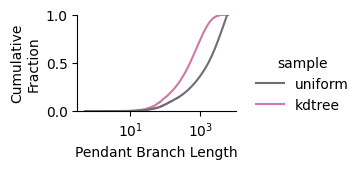

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/hue=sample+kind=ecdf+viz=displot+what=cherry-distances+x=distance+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/hue=sample+kind=ecdf+viz=displot+what=cherry-distances+x=distance+ext=.png


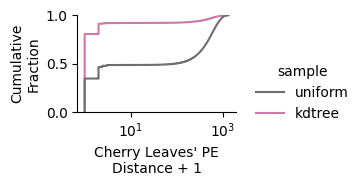

In [ ]:
_palette = dict(zip(SAMPLES, [ETI_PALETTE["neutral"][0], "#CC79A7"]))
for _data, _x, _label, _what, _log in (
    (
        pe_counts,
        "num_genomes",
        "Genomes per\nSampled PE",
        "pe-genomes",
        (True, False),
    ),
    (
        pendant_lengths[pendant_lengths["branch_length"] > 0],
        "branch_length",
        "Pendant Branch Length",
        "pendant-lengths",
        (True, False),
    ),
    (
        cherry_distances.assign(distance=lambda df: df["distance"] + 1),
        "distance",
        "Cherry Leaves' PE\nDistance + 1",
        "cherry-distances",
        (True, False),
    ),
):
    with tp.teed(
        sns.displot,
        data=_data,
        x=_x,
        hue="sample",
        hue_order=[*SAMPLES],
        palette=_palette,
        kind="ecdf",
        log_scale=_log,
        height=1.8,
        aspect=1.4,
        teeplot_outattrs={"what": _what},
        teeplot_outexclude=["palette", "hue_order", "log_scale"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        _g.set_axis_labels(_label, "Cumulative\nFraction")
    plt.close("all")

The kdtree sample is much denser locally.
It packs its genomes into about 55,000 PEs, about 72 per sampled PE, where the uniform sample spreads about 4.5 per PE over about 875,000 PEs.
Its leaves are more closely related: the median pendant branch is about 3.3 times shorter (about 500 vs. 1,700 `origin_time` units), and 81% of its cherries pair two genomes from the same PE (vs. 35%).

## MDC Yield

Number of MDCs (gains observed on non-root branches), split into leaf MDCs (one leaf) and inner MDCs (several leaves), per site and sample.
Gain rate estimates rest on these gains, so more of them should mean more power.

In [ ]:
sample_mdc_counts = (
    sample_mdcs.assign(is_inner=sample_mdcs["num_leaves"] > 1)
    .groupby(["sample", "trait", "kind", "effect_size"], sort=False)
    .agg(
        num_mdcs=("num_leaves", "size"),
        num_inner_mdcs=("is_inner", "sum"),
        mdc_size_mean=("num_leaves", "mean"),
        mdc_size_max=("num_leaves", "max"),
    )
    .reset_index()
)
sample_mdc_counts["num_leaf_mdcs"] = (
    sample_mdc_counts["num_mdcs"] - sample_mdc_counts["num_inner_mdcs"]
)
mo.Html(
    sample_mdc_counts.pivot_table(
        index=["trait", "kind", "effect_size"],
        columns="sample",
        values=["num_mdcs", "num_inner_mdcs", "mdc_size_mean"],
        sort=False,
    ).to_html(float_format="{:.3g}".format),
)

num_mdcs 
 num_inner_mdcs 
 mdc_size_mean 
 
 
 
 
 sample 
 uniform 
 kdtree 
 uniform 
 kdtree 
 uniform 
 kdtree 
 
 
 trait 
 kind 
 effect_size 
 
 
 
 
 
 
 
 
 
 
 site0 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 25.0 
 4.56e+05 
 1.87e+05 
 9.18e+04 
 8.26e+04 
 1.28 
 3.11 
 
 
 site1 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 5.0 
 1.17e+04 
 4.76e+03 
 1.76e+03 
 2.04e+03 
 1.2 
 2.91 
 
 
 site2 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 2.5 
 8.3e+03 
 3.38e+03 
 1.28e+03 
 1.4e+03 
 1.2 
 2.89 
 
 
 site3 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 1.0 
 6.99e+03 
 2.8e+03 
 1.08e+03 
 1.22e+03 
 1.2 
 3.02 
 
 
 site4 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 6.84e+03 
 2.85e+03 
 1.06e+03 
 1.2e+03 
 1.19 
 2.98 
 
 
 site5 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 7.09e+03 
 2.8e+03 
 1.06e+03 
 1.22e+03 
 1.2 
 2.99 
 
 
 site6 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 6.79e+03 
 2.89e+03 
 1.03e+03 
 1.17e+03 
 1.2 
 2.75 
 
 
 site7 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 7.08e+03 
 2.87e+03 
 1.1e+03 
 1.19e+03 
 1.2 
 2.87 
 
 
 site8 
 MLS$|^{-}_{+}$ 
 25.0 
 2.39e+04 
 2.4e+04 
 52 
 243 
 1 
 1.01 
 
 
 site9 
 MLS$|^{-}_{+}$ 
 5.0 
 2.4e+03 
 2.12e+03 
 30 
 300 
 1.01 
 1.2 
 
 
 site10 
 MLS$|^{-}_{+}$ 
 2.5 
 3.19e+03 
 2.2e+03 
 113 
 495 
 1.04 
 1.46 
 
 
 site11 
 MLS$|^{-}_{+}$ 
 1.0 
 4.36e+03 
 2.36e+03 
 425 
 827 
 1.12 
 2.09 
 
 
 site12 
 DEL$\mathit{bg}|^{-}_{\varnothing}$ 
 25.0 
 319 
 331 
 0 
 5 
 1 
 1.02 
 
 
 site13 
 DEL$\mathit{bg}|^{-}_{\varnothing}$ 
 5.0 
 1.48e+03 
 1.25e+03 
 22 
 184 
 1.01 
 1.21 
 
 
 site14 
 DEL$\mathit{bg}|^{-}_{\varnothing}$ 
 2.5 
 2.6e+03 
 1.9e+03 
 96 
 456 
 1.04 
 1.49 
 
 
 site15 
 DEL$\mathit{bg}|^{-}_{\varnothing}$ 
 1.0 
 4.57e+03 
 2.3e+03 
 405 
 759 
 1.1 
 1.99

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/col=what+hue=kind+kind=point+row=sample+viz=catplot+what=mdc-counts+x=effect-size+y=count+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/col=what+hue=kind+kind=point+row=sample+viz=catplot+what=mdc-counts+x=effect-size+y=count+ext=.png


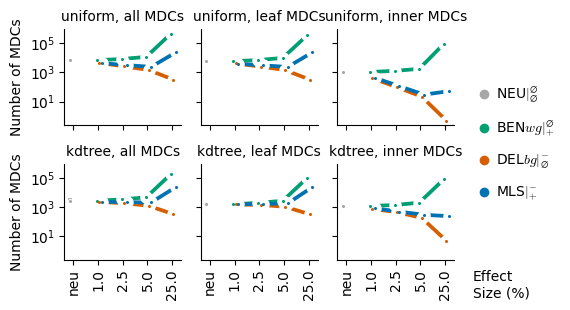

In [ ]:
_what = {
    "num_mdcs": "all",
    "num_leaf_mdcs": "leaf",
    "num_inner_mdcs": "inner",
}
_df = sample_mdc_counts.melt(
    id_vars=["sample", "kind", "effect_size"],
    value_vars=[*_what],
    var_name="what",
    value_name="count",
).assign(
    what=lambda df: df["what"].map(_what),
    count=lambda df: df["count"].clip(lower=0.5),
)
with tp.teed(
    sns.catplot,
    data=_df,
    x="effect_size",
    y="count",
    order=effect_size_order,
    hue="kind",
    hue_order=kind_order,
    palette=kind_palette,
    col="what",
    col_order=[*_what.values()],
    row="sample",
    row_order=[*SAMPLES],
    kind="point",
    errorbar=("pi", 100),
    dodge=0.3,
    height=1.6,
    aspect=1.0,
    log_scale=(False, True),
    teeplot_outattrs={"what": "mdc-counts"},
    teeplot_outexclude=[
        "palette",
        "hue_order",
        "col_order",
        "row_order",
        "dodge",
        "order",
        "log_scale",
    ],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    gap_points(*_g.axes.flat, _g.legend)
    _g.set_axis_labels("", "Number of MDCs")
    _g.set_titles(template="{row_name}, {col_name} MDCs")
    tilt_xticklabels(_g)
    corner_xlabel(_g, right_legend(_g))
plt.close("all")

Dense local sampling trades many separate gains for fewer, larger clades.
For neutral and `BENwg` sites, the kdtree sample has about 2.4 times fewer MDCs (e.g., about 2,850 vs. 6,900 per neutral site), but slightly more inner MDCs, and its MDCs average about 3 leaves (vs. 1.2).
For costly MLS and `DELbg` sites, it sees as many or somewhat fewer MDCs, but many more inner MDCs (e.g., about 300 vs. 30 for MLS at $s = 5\%$), as close relatives are sampled before carrier lineages are lost.

In [ ]:
mo.md(f"""
## Gain Rate Estimates and Power

Each site's gain ratio (gain rate relative to neutral sites') and selection, from each sample, and the evidence for gain ratio ≠ 1: the signed square root of the naive likelihood-ratio statistic, $z = \\mathrm{{sign}}(\\log \\mathrm{{gain\\ ratio}}) \\sqrt{{\\mathrm{{LRT}}}}$, which would be standard normal under the null if the likelihood were not composite.

Nested branches share leaves, so the likelihood is composite and the naive statistic overstates the evidence, possibly by more in a densely sampled tree, which has more nested branches.
So, each statistic is also shown scaled by its sample's mean neutral-site statistic (a rough overdispersion factor; under the null, the mean of a $\\chi^2_1$ statistic is 1): $z_\\mathrm{{adj}} = z / \\sqrt{{\\overline{{\\mathrm{{LRT}}}}_\\mathrm{{neutral}}}}$.
The dashed lines mark $|z| = {scipy_stats.norm.isf(ALPHA / 2):.2f}$, two-sided $\\alpha = {ALPHA}$.
""")

## Gain Rate Estimates and Power

Each site's gain ratio (gain rate relative to neutral sites') and selection, from each sample, and the evidence for gain ratio ≠ 1: the signed square root of the naive likelihood-ratio statistic, $z = \mathrm{sign}(\log \mathrm{gain\ ratio}) \sqrt{\mathrm{LRT}}$, which would be standard normal under the null if the likelihood were not composite.

Nested branches share leaves, so the likelihood is composite and the naive statistic overstates the evidence, possibly by more in a densely sampled tree, which has more nested branches.
So, each statistic is also shown scaled by its sample's mean neutral-site statistic (a rough overdispersion factor; under the null, the mean of a $\chi^2_1$ statistic is 1): $z_\mathrm{adj} = z / \sqrt{\overline{\mathrm{LRT}}_\mathrm{neutral}}$.
The dashed lines mark $|z| = 1.96$, two-sided $\alpha = 0.05$.

In [ ]:
_df = sample_estimates.copy()
for _stat in ("gain_ratio", "selection"):
    _sign = np.sign(
        np.log(_df["gain_ratio"]) if _stat == "gain_ratio" else _df[_stat]
    )
    _df[f"{_stat}_z"] = _sign * np.sqrt(
        _df[f"{_stat}_lrt_naive"].clip(lower=0)
    )
    _neutral = _df["kind"].str.startswith("NEU")
    _scale = (
        _df[_neutral]
        .groupby(["sample", "method", "calibration"])[f"{_stat}_lrt_naive"]
        .mean()
        .rename(f"{_stat}_neutral_lrt_mean")
    )
    _df = _df.merge(_scale, on=["sample", "method", "calibration"])
    _df[f"{_stat}_z_adj"] = _df[f"{_stat}_z"] / np.sqrt(
        _df[f"{_stat}_neutral_lrt_mean"].clip(lower=1.0)
    )
sample_power = _df
_crit = scipy_stats.norm.isf(ALPHA / 2)
power_summary = (
    sample_power[~sample_power["kind"].str.startswith("NEU")]
    .assign(
        detected=lambda df: df["gain_ratio_z"].abs() > _crit,
        detected_adj=lambda df: df["gain_ratio_z_adj"].abs() > _crit,
    )
    .groupby(["method", "calibration", "sample"], sort=False)
    .agg(
        focal_detected=("detected", "sum"),
        focal_detected_adj=("detected_adj", "sum"),
        neutral_lrt_mean=("gain_ratio_neutral_lrt_mean", "first"),
        num_clade_gains=("num_clade_gains", "sum"),
        num_trait_present=("num_trait_present", "sum"),
    )
)
mo.vstack(
    [
        mo.Html(power_summary.to_html(float_format="{:.3g}".format)),
        mo.Html(
            sample_power[
                [
                    "method",
                    "calibration",
                    "sample",
                    "trait",
                    "kind",
                    "effect_size",
                    "configured_gain_ratio",
                    "gain_ratio",
                    "gain_ratio_z",
                    "gain_ratio_z_adj",
                    "selection",
                    "selection_z",
                ]
            ].to_html(float_format="{:.4g}".format),
        ),
    ],
)

focal_detected 
 focal_detected_adj 
 neutral_lrt_mean 
 num_clade_gains 
 num_trait_present 
 
 
 method 
 calibration 
 sample 
 
 
 
 
 
 
 
 
 
 allmdc 
 raw 
 uniform 
 7 
 7 
 1.42 
 9.71e+04 
 429159 
 
 
 calibrated 
 uniform 
 6 
 6 
 1.91 
 9.71e+04 
 429159 
 
 
 pendantmdc 
 raw 
 uniform 
 10 
 10 
 1.34 
 0 
 429159 
 
 
 calibrated 
 uniform 
 6 
 5 
 1.71 
 0 
 429159 
 
 
 allmdc 
 raw 
 kdtree 
 7 
 6 
 3.71 
 9.05e+04 
 144192 
 
 
 calibrated 
 kdtree 
 7 
 6 
 5.52 
 9.05e+04 
 144192 
 
 
 pendantmdc 
 raw 
 kdtree 
 6 
 6 
 1.61 
 0 
 144192 
 
 
 calibrated 
 kdtree 
 6 
 6 
 1.58 
 0 
 144192 
 
 
 
 
 
 
 method 
 calibration 
 sample 
 trait 
 kind 
 effect_size 
 configured_gain_ratio 
 gain_ratio 
 gain_ratio_z 
 gain_ratio_z_adj 
 selection 
 selection_z 
 
 
 
 
 0 
 allmdc 
 raw 
 uniform 
 site4 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 1 
 0.9684 
 -1.445 
 -1.214 
 -0.0001958 
 -20.36 
 
 
 1 
 allmdc 
 raw 
 uniform 
 site5 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 1 
 1.035 
 1.553 
 1.304 
 -0.0002036 
 -21.47 
 
 
 2 
 allmdc 
 raw 
 uniform 
 site6 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 1 
 0.9821 
 -0.8144 
 -0.684 
 -0.0002057 
 -21.29 
 
 
 3 
 allmdc 
 raw 
 uniform 
 site7 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 1 
 1.016 
 0.7119 
 0.5979 
 -0.0001963 
 -20.86 
 
 
 4 
 allmdc 
 raw 
 uniform 
 site0 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 25.0 
 82.72 
 58.09 
 1132 
 950.4 
 -0.0001113 
 -107.3 
 
 
 5 
 allmdc 
 raw 
 uniform 
 site1 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 5.0 
 1.992 
 1.669 
 29.04 
 24.39 
 -0.0001964 
 -26.71 
 
 
 6 
 allmdc 
 raw 
 uniform 
 site2 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 2.5 
 1.389 
 1.17 
 7.683 
 6.453 
 -0.0001886 
 -21.78 
 
 
 7 
 allmdc 
 raw 
 uniform 
 site3 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 1.0 
 1.136 
 0.9842 
 -0.7231 
 -0.6074 
 -0.0001884 
 -19.87 
 
 
 8 
 allmdc 
 raw 
 uniform 
 site8 
 MLS$|^{-}_{+}$ 
 25.0 
 82.72 
 58.2 
 212.3 
 178.3 
 -0.009091 
 -179.8 
 
 
 9 
 allmdc 
 raw 
 uniform 
 site9 
 MLS$|^{-}_{+}$ 
 5.0 
 1.992 
 1.957 
 10.34 
 8.684 
 -0.002728 
 -46.01 
 
 
 10 
 allmdc 
 raw 
 uniform 
 site10 
 MLS$|^{-}_{+}$ 
 2.5 
 1.389 
 1.175 
 4.032 
 3.387 
 -0.001041 
 -41.19 
 
 
 11 
 allmdc 
 raw 
 uniform 
 site11 
 MLS$|^{-}_{+}$ 
 1.0 
 1.136 
 0.9108 
 -3.324 
 -2.792 
 -0.00045 
 -31.46 
 
 
 12 
 allmdc 
 raw 
 uniform 
 site12 
 DEL$\mathit{bg}|^{-}_{\varnothing}$ 
 25.0 
 1 
 0.9411 
 -0.1485 
 -0.1248 
 -0.01116 
 -20.27 
 
 
 13 
 allmdc 
 raw 
 uniform 
 site13 
 DEL$\mathit{bg}|^{-}_{\varnothing}$ 
 5.0 
 1 
 1.121 
 1.395 
 1.172 
 -0.002498 
 -36.69 
 
 
 14 
 allmdc 
 raw 
 uniform 
 site14 
 DEL$\mathit{bg}|^{-}_{\varnothing}$ 
 2.5 
 1 
 1.051 
 1.081 
 0.9081 
 -0.001172 
 -39.33 
 
 
 15 
 allmdc 
 raw 
 uniform 
 site15 
 DEL$\mathit{bg}|^{-}_{\varnothing}$ 
 1.0 
 1 
 0.9869 
 -0.4745 
 -0.3985 
 -0.0004763 
 -33.25 
 
 
 16 
 allmdc 
 calibrated 
 uniform 
 site4 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 1 
 0.9521 
 -1.993 
 -1.442 
 3.303e-06 
 0.318 
 
 
 17 
 allmdc 
 calibrated 
 uniform 
 site5 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 1 
 1.047 
 1.91 
 1.382 
 -1.372e-05 
 -1.35 
 
 
 18 
 allmdc 
 calibrated 
 uniform 
 site6 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 1 
 0.9987 
 -0.05318 
 -0.03848 
 -1.788e-05 
 -1.739 
 
 
 19 
 allmdc 
 calibrated 
 uniform 
 site7 
 NEU$|^{\varnothing}_{\varnothing}$ 
 neu 
 1 
 1.003 
 0.1325 
 0.09587 
 1.45e-06 
 0.143 
 
 
 20 
 allmdc 
 calibrated 
 uniform 
 site0 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 25.0 
 82.72 
 58.54 
 1003 
 725.8 
 6.159e-05 
 55.18 
 
 
 21 
 allmdc 
 calibrated 
 uniform 
 site1 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 5.0 
 1.992 
 1.656 
 25.75 
 18.63 
 1.046e-07 
 0.01325 
 
 
 22 
 allmdc 
 calibrated 
 uniform 
 site2 
 BEN$\mathit{wg}|^{\varnothing}_{+}$ 
 2.5 
 1.389 
 1.163 
 6.678 
 4.832 
 6.074e-06 
 0.6522 
 
 
 23 
 allmdc 
 calibrated 
 uniform 
 site3 
 BEN

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.png


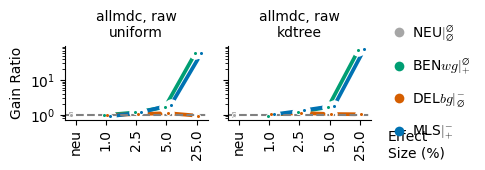

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio-z+viz=catplot+x=effect-size+y=gain-ratio-z+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio-z+viz=catplot+x=effect-size+y=gain-ratio-z+ext=.png


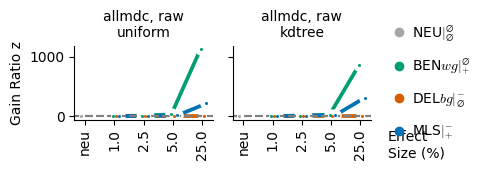

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio-z-adj+viz=catplot+x=effect-size+y=gain-ratio-z-adj+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio-z-adj+viz=catplot+x=effect-size+y=gain-ratio-z-adj+ext=.png


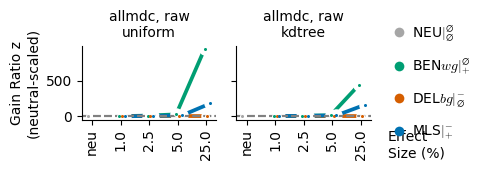

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.png


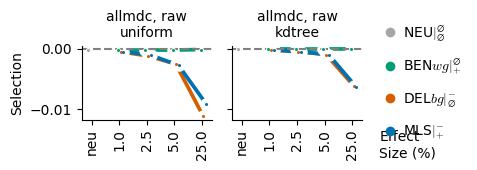

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=selection-z+viz=catplot+x=effect-size+y=selection-z+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=allmdc+stat=selection-z+viz=catplot+x=effect-size+y=selection-z+ext=.png


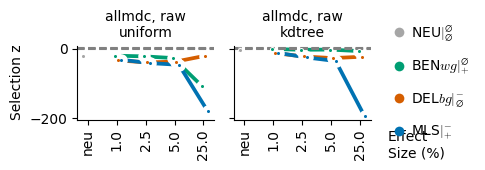

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.png


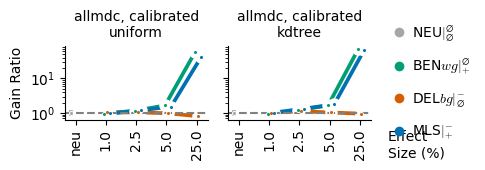

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio-z+viz=catplot+x=effect-size+y=gain-ratio-z+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio-z+viz=catplot+x=effect-size+y=gain-ratio-z+ext=.png


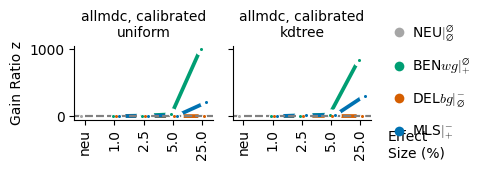

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio-z-adj+viz=catplot+x=effect-size+y=gain-ratio-z-adj+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=gain-ratio-z-adj+viz=catplot+x=effect-size+y=gain-ratio-z-adj+ext=.png


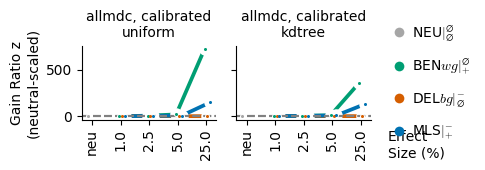

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.png


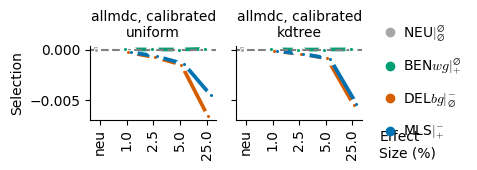

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=selection-z+viz=catplot+x=effect-size+y=selection-z+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=allmdc+stat=selection-z+viz=catplot+x=effect-size+y=selection-z+ext=.png


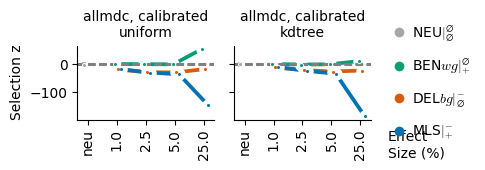

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.png


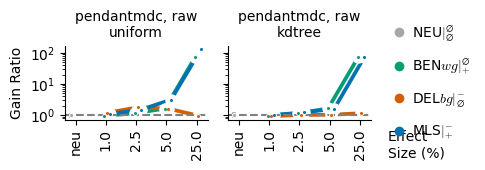

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio-z+viz=catplot+x=effect-size+y=gain-ratio-z+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio-z+viz=catplot+x=effect-size+y=gain-ratio-z+ext=.png


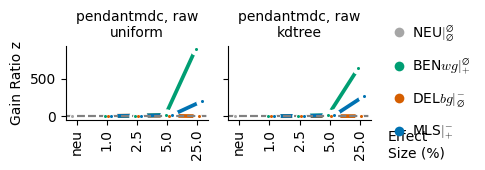

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio-z-adj+viz=catplot+x=effect-size+y=gain-ratio-z-adj+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio-z-adj+viz=catplot+x=effect-size+y=gain-ratio-z-adj+ext=.png


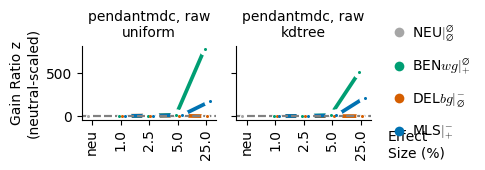

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.png


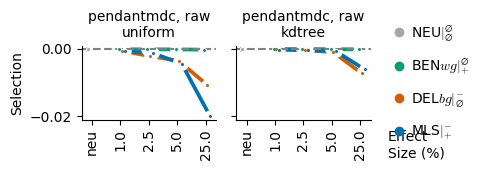

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=selection-z+viz=catplot+x=effect-size+y=selection-z+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=raw+col=sample+hue=kind+kind=point+method=pendantmdc+stat=selection-z+viz=catplot+x=effect-size+y=selection-z+ext=.png


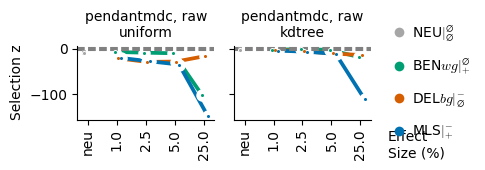

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio+viz=catplot+x=effect-size+y=gain-ratio+ext=.png


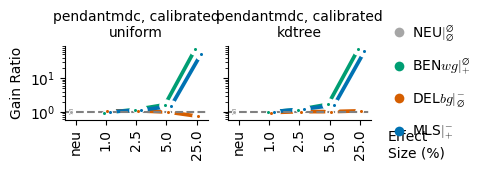

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio-z+viz=catplot+x=effect-size+y=gain-ratio-z+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio-z+viz=catplot+x=effect-size+y=gain-ratio-z+ext=.png


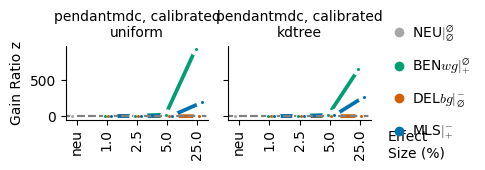

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio-z-adj+viz=catplot+x=effect-size+y=gain-ratio-z-adj+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=gain-ratio-z-adj+viz=catplot+x=effect-size+y=gain-ratio-z-adj+ext=.png


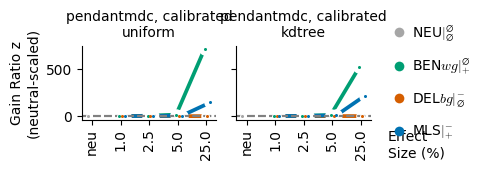

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=selection+viz=catplot+x=effect-size+y=selection+ext=.png


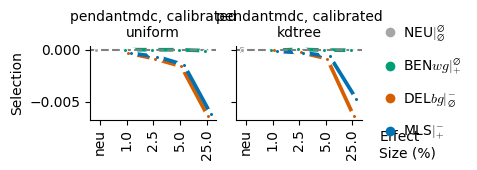

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=selection-z+viz=catplot+x=effect-size+y=selection-z+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/calibration=calibrated+col=sample+hue=kind+kind=point+method=pendantmdc+stat=selection-z+viz=catplot+x=effect-size+y=selection-z+ext=.png


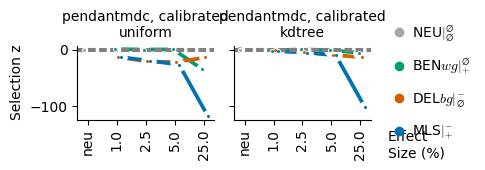

In [ ]:
_crit = scipy_stats.norm.isf(ALPHA / 2)
_labels = {
    "gain_ratio": ("Gain Ratio", True, None),
    "gain_ratio_z": ("Gain Ratio z", False, _crit),
    "gain_ratio_z_adj": ("Gain Ratio z\n(neutral-scaled)", False, _crit),
    "selection": ("Selection", False, None),
    "selection_z": ("Selection z", False, _crit),
}
for (_method, _calibration), _df in sample_power.groupby(
    ["method", "calibration"], sort=False
):
    for _stat, (_label, _log, _ref) in _labels.items():
        with tp.teed(
            sns.catplot,
            data=_df,
            x="effect_size",
            y=_stat,
            order=effect_size_order,
            hue="kind",
            hue_order=kind_order,
            palette=kind_palette,
            col="sample",
            col_order=[*SAMPLES],
            kind="point",
            errorbar=("pi", 100),
            dodge=0.3,
            height=1.8,
            aspect=1.1,
            log_scale=(False, _log),
            teeplot_outattrs={
                "method": _method,
                "calibration": _calibration,
                "stat": _stat.replace("_", "-"),
            },
            teeplot_outexclude=[
                "palette",
                "hue_order",
                "col_order",
                "dodge",
                "order",
                "log_scale",
            ],
            teeplot_show=True,
            teeplot_subdir=pathlib.Path(__file__).stem,
        ) as _g:
            gap_points(*_g.axes.flat, _g.legend)
            if _ref is not None:
                for _y in (-_ref, _ref):
                    _g.refline(y=_y, color="gray", linestyle="--")
            elif _stat == "gain_ratio":
                _g.refline(y=1, color="gray", linestyle="--")
            else:
                _g.refline(y=0, color="gray", linestyle="--")
            _g.set_axis_labels("", _label)
            _g.set_titles(
                col_template=f"{_method}, {_calibration}\n{{col_name}}"
            )
            tilt_xticklabels(_g)
            corner_xlabel(_g, right_legend(_g))
        plt.close("all")

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+stat=gain-ratio-z+viz=relplot+x=gain-ratio-z-uniform+y=gain-ratio-z-kdtree+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+stat=gain-ratio-z+viz=relplot+x=gain-ratio-z-uniform+y=gain-ratio-z-kdtree+ext=.png


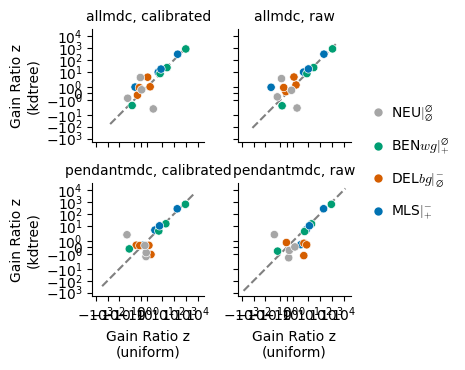

teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+stat=gain-ratio-z-adj+viz=relplot+x=gain-ratio-z-adj-uniform+y=gain-ratio-z-adj-kdtree+ext=.pdf
teeplots/2026-11-05-mls-indiv-spectra-fullgrid-fossils/col=panel+hue=kind+stat=gain-ratio-z-adj+viz=relplot+x=gain-ratio-z-adj-uniform+y=gain-ratio-z-adj-kdtree+ext=.png


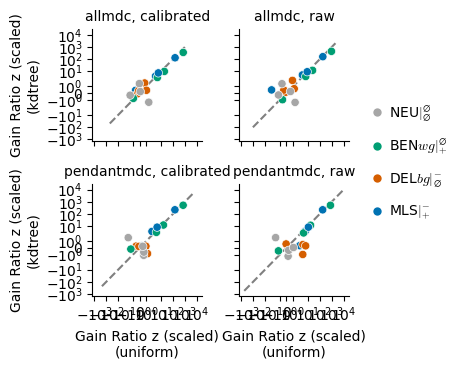

In [ ]:
_uniform, _kdtree = [*SAMPLES]
_wide = sample_power.pivot_table(
    index=["method", "calibration", "trait", "kind", "effect_size"],
    columns="sample",
    values=["gain_ratio_z", "gain_ratio_z_adj"],
)
_wide.columns = [f"{_stat} {_s}" for _stat, _s in _wide.columns]
_wide = _wide.reset_index()
_wide["panel"] = _wide["method"] + ", " + _wide["calibration"]
for _stat in ("gain_ratio_z", "gain_ratio_z_adj"):
    with tp.teed(
        sns.relplot,
        data=_wide,
        x=f"{_stat} {_uniform}",
        y=f"{_stat} {_kdtree}",
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="panel",
        col_wrap=2,
        height=1.9,
        aspect=1.0,
        teeplot_outattrs={"stat": _stat.replace("_", "-")},
        teeplot_outexclude=["palette", "hue_order", "col_wrap"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        for _ax in _g.axes.flat:
            _lo, _hi = (
                min(_ax.get_xlim()[0], _ax.get_ylim()[0]),
                max(_ax.get_xlim()[1], _ax.get_ylim()[1]),
            )
            _ax.plot(
                [_lo, _hi],
                [_lo, _hi],
                color="gray",
                linestyle="--",
                zorder=0,
            )
            _ax.set_xscale("symlog", linthresh=2)
            _ax.set_yscale("symlog", linthresh=2)
        _name = "Gain Ratio z" + (
            " (scaled)" if _stat.endswith("adj") else ""
        )
        _g.set_axis_labels(
            f"{_name}\n({_uniform})", f"{_name}\n({_kdtree})"
        )
        _g.set_titles(col_template="{col_name}")
        right_legend(_g)
    plt.close("all")

### Notes

- **MLS sites:** the kdtree sample gives more evidence that gain rate exceeds neutral sites'.
  With calibrated pendant fits, whose neutral sites' statistics are near their null scale in both samples (mean neutral LRT about 1.6–1.7), $z$ rises from 6.0 to 10.0 at $s = 5\%$ and from 2.5 to 4.4 at $s = 2.5\%$; with calibrated allmdc fits, from 8.0 to 17.0 and from 4.7 to 9.3.
  Its MLS gain ratio estimates are also closer to the configured ones (allmdc, calibrated: 1.78 vs. 1.54 at $s = 5\%$, configured 1.99; 68 vs. 42 at $s = 25\%$, configured 82.7), as gains are seen on short branches before between-host cost removes their carriers.
- **`BENwg` sites:** the kdtree sample gives less evidence (e.g., calibrated pendant $z$ 15.0 vs. 20.5 at $s = 5\%$), as these sites carry no cost, so the uniform sample's 2.4-fold more independent gains count for more.
- **Null calibration:** the allmdc statistics are overdispersed in the kdtree sample: its neutral sites' mean gain ratio LRT is 5.5 (calibrated) vs. 1.9 for the uniform sample, and one `DELbg` site reaches $z = 3.5$.
  Denser sampling nests more branches, so the composite likelihood overstates the evidence more.
  Scaled by the neutral mean, the kdtree's MLS advantage shrinks (e.g., $z_\mathrm{adj}$ 7.2 vs. 5.8 at $s = 5\%$) and its `BENwg` deficit grows (9.6 vs. 18.6); with four neutral sites, this scaling is rough.
- **Selection:** the kdtree sample gives less evidence of between-host cost, especially for pendant fits (e.g., MLS at $s = 5\%$: $z = -9.4$ vs. $-25.9$), as its short pendant branches leave little time for cost to act.
- So, k-d tree group sampling does sample local clusters densely, and that improves power to detect raised gain rates of costly (MLS) traits, but it costs power for cost-free (`BENwg`) traits and for detecting between-host cost, and allmdc's naive statistics need a null calibration to compare across samples.